In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

import scanpy as sc
import scvi
import pathlib
import warnings
import gc
import os
warnings.filterwarnings('ignore')

sc.set_figure_params(figsize=(4, 4))

[rank: 0] Global seed set to 0


In [2]:
#Heart atlas with subclustering
Heart = sc.read_h5ad("/rwthfs/rz/cluster/home/noco0013/projects/novo_postdoc/data/Heart/scVI_Heart_atlas_TB_Subclustering.h5ad")

In [3]:
Heart.obs["Condition"] = Heart.obs["Condition"].replace('Healthy', 'Control')
Heart.obs["Ischemia"] = Heart.obs["Ischemia"].replace('Healthy', 'Control')
Heart.obs["Ischemia"] = Heart.obs["Ischemia"].replace('Ischemia', 'Long_term')
Heart.obs["Ischemia"] = Heart.obs["Ischemia"].replace('fibrotic', 'Fibrotic')
Heart.obs["Ischemia"] = Heart.obs["Ischemia"].replace('ischemic', 'Ischemic')
Heart.obs["Ischemia"] = Heart.obs["Ischemia"].replace('myogenic', 'Myogenic')
Heart.obs["Ischemia"] = Heart.obs["Ischemia"].replace('non-ischemic', 'Non_ischemic')

In [4]:
Heart.obs["Condition2"] = Heart.obs["Condition"]
Heart.obs["Condition"] = Heart.obs["Condition"].replace('myocardial infarction', 'MI')
Heart.obs["Condition"] = Heart.obs["Condition"].replace('Long-term ischemic', 'MI_Long_term')
Heart.obs["Condition"] = Heart.obs.apply(lambda row: f"{row['Condition']}_{row['Ischemia']}" if row['Condition'] == 'MI' else row['Condition'], axis=1)

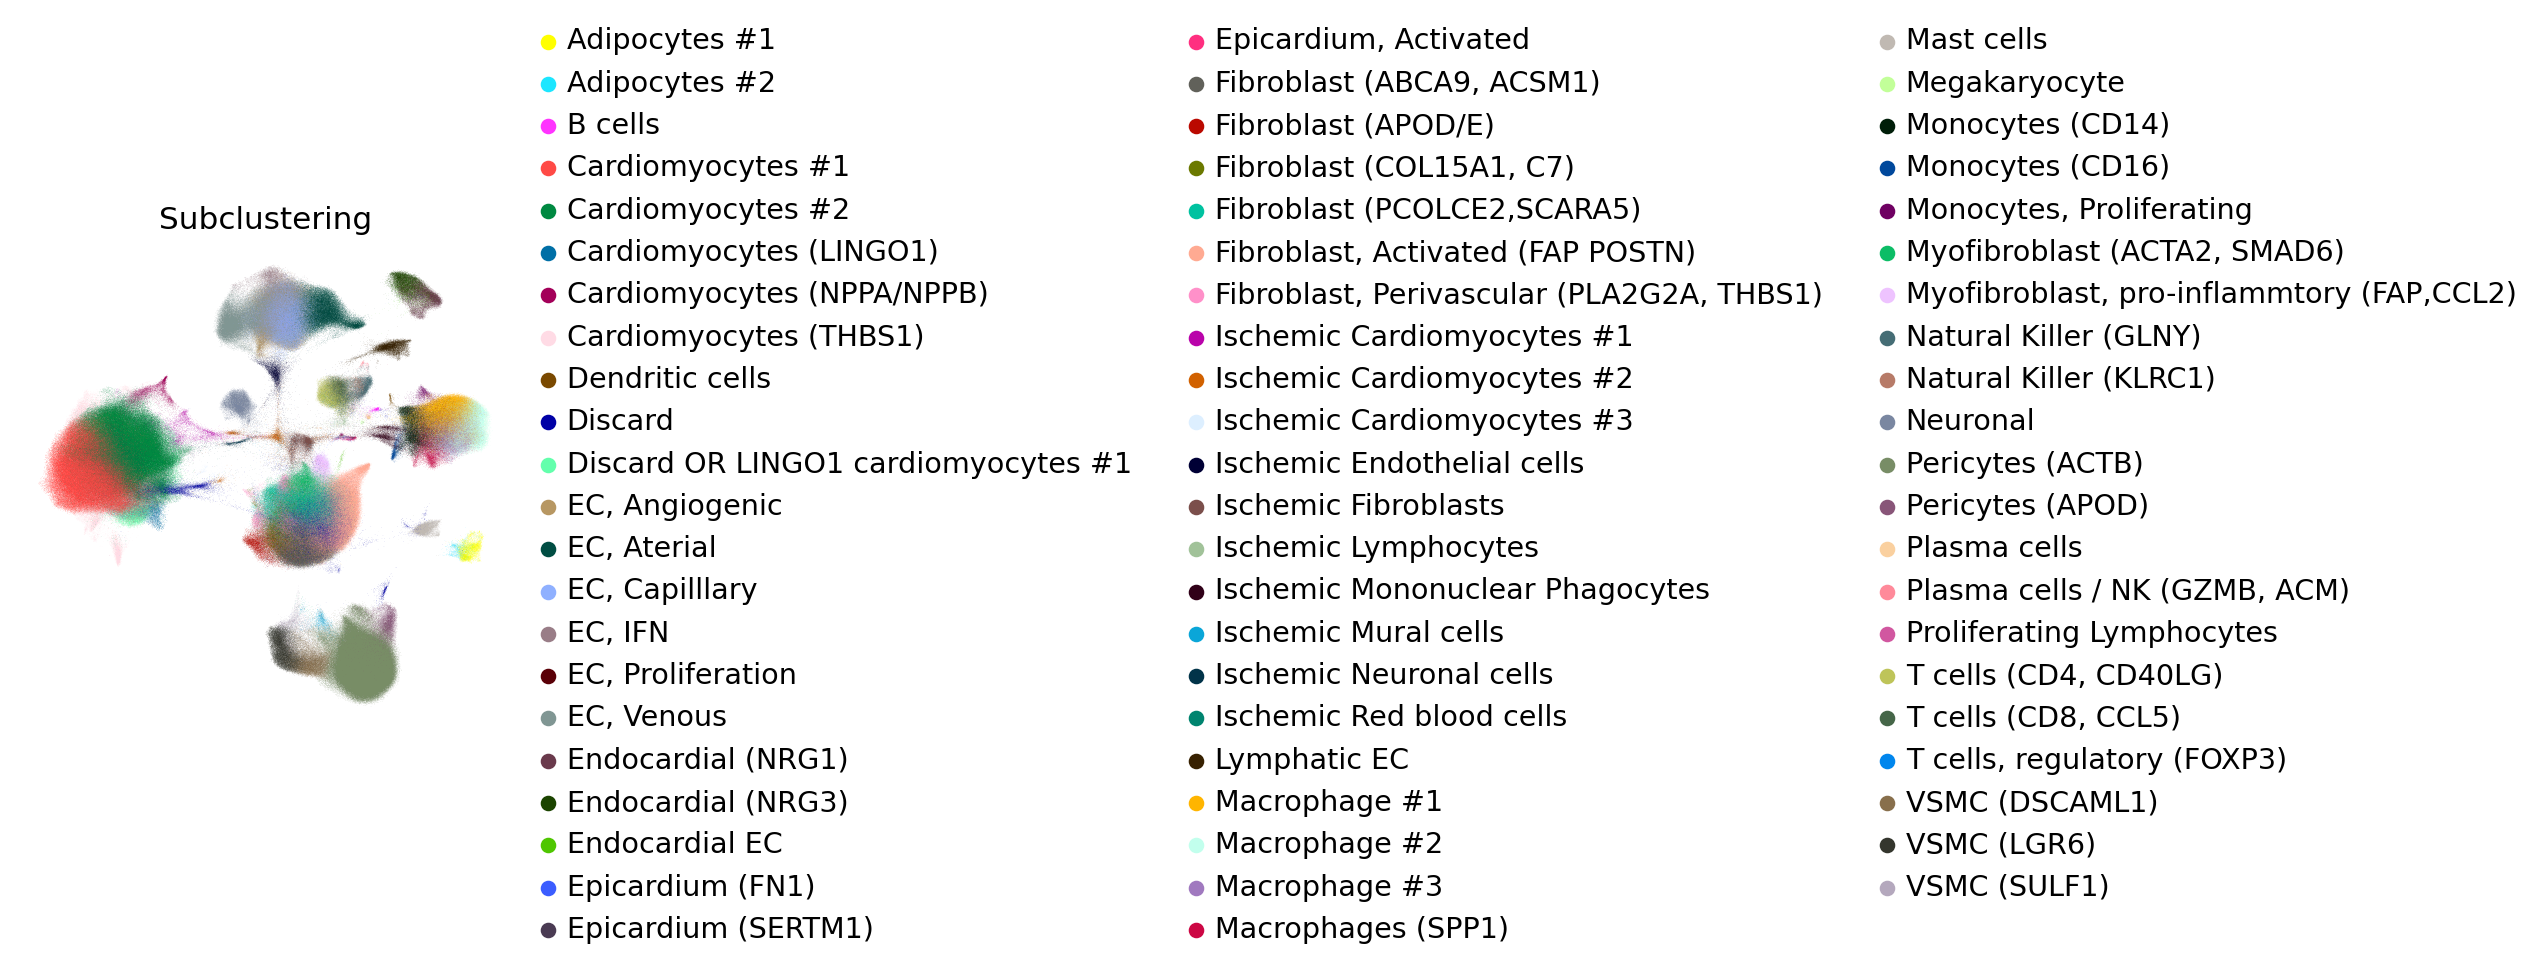

In [5]:
sc.pl.umap(
    Heart,
    color=["Subclustering"],
    frameon=False, ncols=1)

In [5]:
def Pan_aggregation(anndata, groupby_col='Donor', columns_to_aggregate="all", cluster_column=None, agg_func='sum', layer=None, gene_symbols=None):
    if columns_to_aggregate == 'all':
        columns_to_aggregate = [col for col in anndata.obs.columns if col != groupby_col]
    if groupby_col is None:
        print("Please provide columns for the aggregation")
    else:
        numeric_cols = [col for col in columns_to_aggregate if anndata.obs[col].dtype.kind in 'iufc']
        non_numeric_cols = [col for col in columns_to_aggregate if col not in numeric_cols]

        agg_dict = {col: 'mean' if col in numeric_cols else lambda x: ', '.join(set(x.astype(str))) for col in columns_to_aggregate}

        grouped = anndata.obs.groupby(groupby_col)
        obs = grouped.agg(agg_dict)
        obs.index.name = groupby_col

        if cluster_column:
            value_counts = anndata.obs.groupby(groupby_col)[cluster_column].value_counts().unstack(fill_value=0)
            sums_per_group = value_counts.sum(axis=1)
            result = value_counts.div(sums_per_group, axis=0).fillna(0)
            obs = obs.merge(result, left_index=True, right_index=True)

        agg_functions = {
            'sum': np.sum,
            'mean': np.mean,
            'median': np.median,
        }

        if layer is not None:
            getX = lambda x: x.layers[layer]
        else:
            getX = lambda x: x.X

        if gene_symbols is not None:
            new_idx = anndata.var[gene_symbols]
        else:
            new_idx = anndata.var_names

        grouped_data = anndata.obs.groupby(groupby_col)
        out = pd.DataFrame(
            np.zeros((anndata.shape[1], len(grouped_data)), dtype=np.float64),
            columns=list(grouped_data.groups.keys()),
            index=anndata.var_names
        )

        for group, idx in grouped_data.indices.items():
            X = getX(anndata[idx])
            if agg_func in agg_functions:
                out[group] = np.ravel(agg_functions[agg_func](X, axis=0))
            else:
                raise ValueError("Invalid aggregation function. Choose from 'sum', 'mean', 'median'.")

        new_anndata = sc.AnnData(out.T, obs, anndata.var)
        return new_anndata

# Example usage:
#new_anndata = Pan_aggregation(Heart, groupby_col='Donor', cluster_column='Annotation_1', agg_func='sum')


In [6]:
gc.collect()
Heart = Heart.raw.to_adata()

In [7]:
Heart = Heart[~(Heart.obs["Subclustering"].isin(["Discard", 'Ischemic Red blood cells',]))]

In [8]:
gc.collect()
Heart.obs["Subclustering"] = Heart.obs["Subclustering"].replace('Discard OR LINGO1 cardiomyocytes #1', 'Cardiomyocytes (LINGO1)')

In [9]:
gc.collect()

1323

In [10]:

anndata_sub = Pan_aggregation(Heart, groupby_col='Donor', cluster_column='Subclustering', agg_func='mean')
anndata_sub.write("/rwthfs/rz/cluster/hpcwork/noco0013/projects/novo_postdoc/data/Heart_Donor_mean_Subclustering.h5ad")

In [11]:
gc.collect()
anndata_main = Pan_aggregation(Heart, groupby_col='Donor', cluster_column='Annotation_1', agg_func='mean')
anndata_main.write("/rwthfs/rz/cluster/hpcwork/noco0013/projects/novo_postdoc/data/PanPy_Heart_Donor_Annotation.h5ad")